# RAG Assignment — Baseline (Bi-Encoder) vs. Re-Ranking (Cross-Encoder)

**Document:** *FIDE Arbiters' Manual 2026* (365 content pages): the Laws of Chess with official commentary, rapid/blitz appendices, anti-cheating rules, Swiss pairing systems, rating/title regulations, tie-break rules and online/hybrid chess regulations.

**Why this document is a good stress test**

* The **same concept appears in many regulatory contexts** (over-the-board vs. online vs. hybrid, standard vs. rapid vs. blitz). So there are lots of lexically similar distractor passages.
* Rules are full of **exceptions** ("…unless…", "However, the game is drawn if…") and **prohibitions** ("must not", "is not allowed to"). Those are exactly what a single-vector bi-encoder tends to blur.

**What this notebook does**

| Step | What happens |
|---|---|
| 1–2 | Extract text from the PDF and split it into overlapping chunks |
| 3–4 | Embed every chunk with a **bi-encoder** and index the vectors in FAISS |
| 5 | **Pipeline 1 (baseline):** top-10 by cosine similarity → top-3 go to the LLM → *Answer 1* |
| 6 | **Pipeline 2 (re-rank):** same top-10 → **cross-encoder** scores each (query, chunk) pair → new top-3 → *Answer 2* |
| 7–10 | Failure-mode analysis: rank shifts, retrieval metrics, chunk-level inspection |
| 11 | LLM answers for both pipelines, using an identical prompt |
| 12–13 | Latency profiling, plus a full-corpus cross-encoder experiment for the scaling question |

> **Running it:** open in Google Colab → *Runtime → Run all*. For the LLM step, add a Gemini API key as a Colab secret named `GEMINI_API_KEY`. If there is no key, the notebook falls back to a local open-weights model (`Qwen2.5-1.5B-Instruct`). Pick a GPU runtime for that.

In [1]:
# ── 0. Install dependencies (Colab already has torch / transformers) ─────────────────────────
%pip install -q sentence-transformers faiss-cpu pymupdf google-genai pandas matplotlib

# In Colab, fetch the repo (PDF + folders) if the notebook was opened on its own
import os, sys
REPO_URL = "https://github.com/Zenith053/rag-reranking-arbiter.git"
if "google.colab" in sys.modules and not os.path.exists("data/Arbiter-Manual-2026.pdf"):
    !git clone -q {REPO_URL}
    %cd rag-reranking-arbiter

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ── 0. Imports and global configuration ─────────────────────────────────────────────────────
import os, re, json, time, statistics, textwrap, pathlib
import numpy as np, pandas as pd
import pymupdf                      # PyMuPDF: PDF → text
import faiss                        # vector index (exact inner-product search)
import torch
from sentence_transformers import SentenceTransformer, CrossEncoder
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)

# Paths
PDF_PATH    = "data/Arbiter-Manual-2026.pdf"     # in Colab: upload the PDF, or clone the repo first
RESULTS_DIR = pathlib.Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

# Models. LOCAL_MODEL_DIR is only an override for offline machines holding copies of the same weights.
LOCAL_MODEL_DIR = os.environ.get("LOCAL_MODEL_DIR")
EMBED_MODEL  = f"{LOCAL_MODEL_DIR}/all-MiniLM-L6-v2" if LOCAL_MODEL_DIR else "sentence-transformers/all-MiniLM-L6-v2"
RERANK_MODEL = f"{LOCAL_MODEL_DIR}/ms-marco-MiniLM-L-6-v2" if LOCAL_MODEL_DIR else "cross-encoder/ms-marco-MiniLM-L-6-v2"

# Retrieval hyper-parameters (fixed by the assignment: retrieve 10, keep 3)
TOP_K_RETRIEVE = 10
TOP_N_CONTEXT  = 3

# Chunking hyper-parameters
CHUNK_WORDS   = 180   # median ≈ 240 WordPiece tokens, close to the bi-encoder's 256-token window (truncation checked in §3)
OVERLAP_WORDS = 40    # overlap so a rule that straddles a boundary still appears whole in at least one chunk

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| embed:", EMBED_MODEL, "| rerank:", RERANK_MODEL)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | embed: /home/claude/local_models/all-MiniLM-L6-v2 | rerank: /home/claude/local_models/ms-marco-MiniLM-L-6-v2


## 1. Load the PDF

PDF pages 1–9 are the cover, forewords and the table of contents. The TOC is dot-leader noise that repeats every section title, so it would act as an artificial distractor. Content starts on printed page 1 (PDF index 9), so page numbers below match the **printed page numbers** of the manual. Bare page-number lines (header/footer artefacts) are removed.

In [3]:
FIRST_CONTENT_PAGE = 9   # PDF index of printed page "1"

def load_pages(path=PDF_PATH):
    # Return [{'page': printed_page_no, 'text': cleaned_text}, ...]
    doc = pymupdf.open(path)
    pages = []
    for i in range(FIRST_CONTENT_PAGE, len(doc)):
        lines = [l.strip() for l in doc[i].get_text().splitlines()]
        lines = [l for l in lines if l and not re.fullmatch(r"\d{1,3}", l)]   # drop page-number lines
        pages.append({"page": i - FIRST_CONTENT_PAGE + 1, "text": " ".join(lines)})
    return pages

pages = load_pages()
print(f"{len(pages)} content pages, {sum(len(p['text'].split()) for p in pages):,} words")
print(pages[30]["text"][:400], "…")

365 content pages, 140,614 words
Article 9: The Drawn Game 9.1 Draw offers and event regulations: 9.1.1 The regulations of an event may specify that players cannot offer or agree to a draw, whether in less than a specified number of moves or at all, without the consent of the arbiter. 9.1.2 However, if the regulations of an event allow a draw agreement the following shall apply: 9.1.2.1 A player wishing to offer a draw shall do s …


## 2. Chunking

A **sliding window of 180 words with a 40-word overlap**, run over the whole document as one word stream, so chunks can cross page boundaries. Each chunk remembers the page(s) it came from.

*Why not chunk by article?* The manual interleaves official Law text with the Commission's commentary, and article numbering differs between sections (Laws 1–12, Appendix A.x, Guidelines III.x, C.04 articles…). A fixed window is simple and reproducible, and it is the standard baseline setting. **The exact same chunk list is used by both pipelines.**

In [4]:
def chunk_pages(pages, size=CHUNK_WORDS, overlap=OVERLAP_WORDS):
    words, page_of = [], []
    for p in pages:
        w = re.sub(r"\s+", " ", p["text"]).split(" ")
        words += w
        page_of += [p["page"]] * len(w)          # page number for every word
    chunks, step = [], size - overlap
    for start in range(0, len(words), step):
        end = min(start + size, len(words))
        chunks.append({"id": len(chunks),
                       "text": " ".join(words[start:end]),
                       "page_start": page_of[start], "page_end": page_of[end - 1]})
        if end == len(words):
            break
    return chunks

chunks = chunk_pages(pages)
chunk_texts = [c["text"] for c in chunks]
print(f"{len(chunks)} chunks | words per chunk: {CHUNK_WORDS} (overlap {OVERLAP_WORDS})")
print("example:", chunks[87]["page_start"], "→", chunks[87]["text"][:300], "…")

1005 chunks | words per chunk: 180 (overlap 40)
example: 33 → 9.4 If the player touches a piece as in Article 4.3, he/she loses the right to claim a draw under Article 9.2 or 9.3 on that move. 9.5 Draw claims: 9.5.1 If a player claims a draw under Article 9.2 or 9.3, he/she or the arbiter shall pause the chessclock. He/She is not allowed to withdraw his/her cl …


## 3. Load the two encoders

| | **Bi-encoder** `all-MiniLM-L6-v2` | **Cross-encoder** `ms-marco-MiniLM-L-6-v2` |
|---|---|---|
| Input | one text at a time | the *pair* `[CLS] query [SEP] chunk [SEP]` |
| Output | a 384-d vector per text | one relevance logit per pair |
| Similarity | $\cos(\mathbf{q},\mathbf{d}) = \dfrac{\mathbf{q}\cdot\mathbf{d}}{\lVert\mathbf{q}\rVert\,\lVert\mathbf{d}\rVert}$ | $s(q,d) = \mathbf{w}^\top \mathrm{BERT}([q;d])_{\texttt{[CLS]}} + b$ |
| Can pre-compute documents? | **yes**: index once, then one query encode per search | **no**: one full transformer pass per (query, chunk) |

Both are 6-layer MiniLM transformers, so the comparison isolates the *architecture* (independent vs. joint encoding), not model size.

In [5]:
bi_encoder    = SentenceTransformer(EMBED_MODEL, device=DEVICE)
cross_encoder = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)

# Truncation check: the bi-encoder only reads the first 256 tokens of a chunk; the cross-encoder reads up to 512 (query + chunk).
tok_len = np.array([len(bi_encoder.tokenizer(t)["input_ids"]) for t in chunk_texts])
print(f"bi-encoder window = {bi_encoder.max_seq_length} tokens | chunk tokens: median {np.median(tok_len):.0f}, "
      f"p90 {np.percentile(tok_len, 90):.0f}, max {tok_len.max()} | {np.mean(tok_len > bi_encoder.max_seq_length):.0%} of chunks lose their tail in the bi-encoder")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7758.72it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 9573.12it/s]


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (258 > 256). Running this sequence through the model will result in indexing errors


bi-encoder window = 256 tokens | chunk tokens: median 240, p90 289, max 736 | 24% of chunks lose their tail in the bi-encoder


## 4. Index all chunks in a vector store (FAISS)

Embeddings are **L2-normalised**, so the inner product equals cosine similarity: $\mathbf{q}\cdot\mathbf{d} = \cos(\mathbf{q},\mathbf{d})$ when $\lVert\mathbf{q}\rVert=\lVert\mathbf{d}\rVert=1$. `IndexFlatIP` does exact (brute-force) inner-product search. With about 1,000 vectors an approximate index (HNSW/IVF) would add nothing.

In [6]:
t0 = time.perf_counter()
chunk_emb = bi_encoder.encode(chunk_texts, batch_size=64, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=True).astype(np.float32)
index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
INDEX_BUILD_S = time.perf_counter() - t0
print(f"indexed {index.ntotal} vectors of dim {chunk_emb.shape[1]} in {INDEX_BUILD_S:.1f}s (one-off cost)")

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   6%|▋         | 1/16 [00:02<00:36,  2.42s/it]

Batches:  12%|█▎        | 2/16 [00:04<00:33,  2.39s/it]

Batches:  19%|█▉        | 3/16 [00:07<00:30,  2.37s/it]

Batches:  25%|██▌       | 4/16 [00:09<00:29,  2.46s/it]

...

Batches:  88%|████████▊ | 14/16 [00:33<00:04,  2.34s/it]

Batches:  94%|█████████▍| 15/16 [00:35<00:02,  2.32s/it]

Batches: 100%|██████████| 16/16 [00:37<00:00,  2.10s/it]

Batches: 100%|██████████| 16/16 [00:37<00:00,  2.33s/it]

indexed 1005 vectors of dim 384 in 37.3s (one-off cost)


## 5. Pipeline 1 — Baseline retrieval (bi-encoder)

a) encode the query → b) take the top-10 chunks by cosine similarity → c) the **first 3** go to the LLM.

In [7]:
def baseline_retrieve(query, k=TOP_K_RETRIEVE):
    # Pipeline 1: dense retrieval. Returns k candidates sorted by cosine similarity.
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    scores, ids = index.search(q, k)
    return [{"chunk_id": int(i), "bi_score": float(s), "bi_rank": r + 1}
            for r, (i, s) in enumerate(zip(ids[0], scores[0]))]

demo = baseline_retrieve("What is the penalty for an incorrect draw claim?")
pd.DataFrame(demo).assign(page=lambda d: [chunks[i]["page_start"] for i in d.chunk_id],
                          text=lambda d: [chunks[i]["text"][:90] for i in d.chunk_id])

,chunk_id,bi_score,bi_rank,page,text
0,81,0.685597,1,31,"the players to draw in less than the specified number of moves, which must be accepted by"
1,85,0.667863,2,32,need to check the correctness of the claim. But be careful. If there is a draw restriction
2,88,0.625035,3,33,in 9.2.2 at least five times. 9.6.2 any series of at least 75 moves have been made by each
3,84,0.597396,4,32,"1. make a move 2. offer of a draw 3. press the clock If a player deviates from this order,"
4,89,0.587817,5,33,"of Article 4 are also valid. In 9.6.1 case, the five times need not be consecutive. In bot"
5,87,0.586254,6,33,"9.4 If the player touches a piece as in Article 4.3, he/she loses the right to claim a dra"
6,86,0.585651,7,32,"write his/her intended move, it is advisable that instead of rejecting the claim, the arbi"
7,951,0.569673,8,337,"draw claim tool, if this position occurred three times (1). After checking the Arbiter sha"
8,109,0.562903,9,41,"by the players without intervention of the arbiter. A.5.3 To claim a win on time, the clai"
9,80,0.555978,10,31,be attached to the offer. In both cases the offer cannot be withdrawn and remains valid un


## 6. Pipeline 2 — Cross-encoder re-ranking

a) take the **same** 10 candidates → b) score each `(query, chunk)` pair with the cross-encoder → c) sort by that score, descending → d) the new top-3 go to the LLM with the identical prompt.

The re-ranker can only **re-order** what the bi-encoder found. If the right chunk is not in the top-10 (a *recall* failure), re-ranking cannot recover it. Section 10 shows a case of this.

In [8]:
def rerank(query, candidates):
    # Pipeline 2: re-score the bi-encoder candidates jointly with the query.
    pairs  = [(query, chunks[c["chunk_id"]]["text"]) for c in candidates]
    scores = cross_encoder.predict(pairs, batch_size=len(pairs), show_progress_bar=False)
    out = [dict(c, ce_score=float(s)) for c, s in zip(candidates, scores)]
    out.sort(key=lambda d: d["ce_score"], reverse=True)
    for r, d in enumerate(out):
        d["ce_rank"] = r + 1
    return out

pd.DataFrame(rerank("What is the penalty for an incorrect draw claim?", demo))[["chunk_id","bi_rank","ce_rank","bi_score","ce_score"]]

,chunk_id,bi_rank,ce_rank,bi_score,ce_score
0,84,4,1,0.597396,1.952733
1,87,6,2,0.586254,1.716039
2,85,2,3,0.667863,1.501201
3,81,1,4,0.685597,0.626776
4,88,3,5,0.625035,0.179166
5,951,8,6,0.569673,-0.039245
6,86,7,7,0.585651,-1.883487
7,109,9,8,0.562903,-3.121735
8,89,5,9,0.587817,-3.239120
9,80,10,10,0.555978,-6.066735


## 7. The generator (LLM) and the shared prompt

Both pipelines use **exactly the same prompt template**. Only the three context chunks differ. The prompt tells the model to answer *only* from the context and to say so when the context is insufficient. That makes hallucination and omission visible when the right chunk was not retrieved.

Backend selection:
* `gemini` (default when a `GEMINI_API_KEY` is available): `gemini-flash-latest` (the current Flash model; the resolved version is saved with the answers), temperature 0
* `hf`: local `Qwen/Qwen2.5-1.5B-Instruct`, greedy decoding
* `none`: skip generation (prints the prompt). Used only for retrieval-only runs.

In [9]:
PROMPT_TEMPLATE = '''You are an assistant answering questions about the FIDE Arbiters' Manual 2026.
Answer the question using ONLY the context passages below. Quote the relevant rule or article number when possible.
If the context does not contain the information needed, say "The provided context does not contain this information."
Do not use outside knowledge.

### Context
{context}

### Question
{question}

### Answer
'''

def build_prompt(question, ranked):
    ctx = "\n\n".join(f"[Passage {n+1} | p.{chunks[d['chunk_id']]['page_start']}]\n{chunks[d['chunk_id']]['text']}"
                      for n, d in enumerate(ranked[:TOP_N_CONTEXT]))
    return PROMPT_TEMPLATE.format(context=ctx, question=question)

# ---- pick a backend ----
def _gemini_key():
    try:
        from google.colab import userdata
        return userdata.get("GEMINI_API_KEY")
    except Exception:
        return os.environ.get("GEMINI_API_KEY")

GEMINI_KEY   = _gemini_key()
LLM_BACKEND  = os.environ.get("LLM_BACKEND") or ("gemini" if GEMINI_KEY else "hf")
GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-flash-latest")   # alias → current GA Flash model
HF_MODEL     = "Qwen/Qwen2.5-1.5B-Instruct"

if LLM_BACKEND == "gemini":
    from google import genai
    from google.genai import types
    gclient = genai.Client(api_key=GEMINI_KEY)
elif LLM_BACKEND == "hf":
    from transformers import AutoTokenizer, AutoModelForCausalLM
    hf_tok = AutoTokenizer.from_pretrained(HF_MODEL)
    hf_llm = AutoModelForCausalLM.from_pretrained(HF_MODEL, dtype="auto", device_map="auto")

def generate(prompt, max_tokens=350):
    # Returns (answer_text, seconds). Deterministic decoding for a fair A/B comparison.
    t0 = time.perf_counter()
    if LLM_BACKEND == "gemini":
        # generous token budget: newer Flash models spend part of it on internal "thinking"
        cfg = types.GenerateContentConfig(temperature=0.0, max_output_tokens=4096)
        for attempt in range(6):                       # simple back-off for free-tier rate limits
            try:
                resp = gclient.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=cfg)
                text = resp.text
                globals()["GEMINI_RESOLVED"] = getattr(resp, "model_version", GEMINI_MODEL)
                break
            except Exception as e:
                if attempt == 5: raise
                print("  retrying after error:", str(e)[:80]); time.sleep(10 * (attempt + 1))
    elif LLM_BACKEND == "hf":
        msgs = [{"role": "user", "content": prompt}]
        inputs = hf_tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt",
                                            return_dict=True).to(hf_llm.device)
        out = hf_llm.generate(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
                              max_new_tokens=max_tokens, do_sample=False)
        text = hf_tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    else:
        text = None
    return (text.strip() if text else None), time.perf_counter() - t0

print("LLM backend:", LLM_BACKEND)

LLM backend: none


## 8. Test queries

Each query has a **gold phrase**: a verbatim fragment of the clause that actually answers it, found by reading the manual. Any chunk that contains a gold phrase counts as relevant. Phrases are used instead of hard-coded chunk ids so the evaluation survives changes to the chunking parameters.

* **Failure queries** (`F*`): the stress tests the assignment asks for, grouped by failure mode.
* **Counter-examples** (`X*`): cases where re-ranking does *not* help, included for an honest picture.
* **General queries** (`G*`): ordinary questions, used only for the aggregate metrics.

In [10]:
QUERIES = [
  # id,  category,                    query,                                                                                   gold phrase(s)
  ("F1", "Keyword trap / synonym",    "Can a spectator tell the arbiter that a player's time has run out?",                      ["If a spectator sees a flag fall"]),
  ("F2", "Keyword trap / distractor", "Can a player who arrives late still store their mobile phone before playing?",            ["opportunity to store his/her device"]),
  ("F3", "Exception / corner case",   "Can a player claim threefold repetition after touching a piece?",                         ["loses the right to claim a draw under Article 9.2", "loses the right to claim 3 fold"]),
  ("F4", "Exception / penalty",       "What is the penalty for an incorrect draw claim?",                                        ["If the claim is found to be incorrect, the arbiter shall add two minutes"]),
  ("F5", "Negation / constraint",     "Which tie-breaks must not be used in round-robin tournaments?",                           ["These tie-breaks must not be used in round-robins"]),
  ("F6", "Buried (rank 4-10)",        "What happens if neither player keeps score in time trouble and a flag falls?",            ["If neither player keeps score under Article 8.4"]),
  ("F7", "Buried (rank 4-10)",        "What should the arbiter do if both flags have fallen and it is impossible to tell which fell first?", ["impossible to establish which flag fell first then"]),
  ("X1", "Counter: CE demotes gold",  "When must the arbiter call a flag fall in rapid chess?",                                   ["shall also call a flag fall"]),
  ("X2", "Counter: CE demotes gold",  "Can a player smoke during an online game with supervision?",                               ["not permitted when visible on camera", "merely from smoking in a visible manner"]),
  ("X3", "Counter: recall ceiling",   "Can two players agree a draw before any moves have been made?",                           ["provided both players have made at least one move"]),
  ("G1", "General", "Is the arbiter allowed to tell a player how many moves remain until the time control?", ["The arbiter must not answer this"]),
  ("G2", "General", "Is a player allowed to castle after deliberately touching the rook first and then the king?", ["deliberately touches a rook and then his/her king"]),
  ("G3", "General", "Can two participants in a Swiss tournament play each other twice?",          ["shall not play against each other more than once"]),
  ("G4", "General", "Is the arbiter allowed to inform a player that the opponent has completed a move?", ["refrain from informing a player that his/her opponent"]),
  ("G5", "General", "Can a draw offer have conditions attached?",                                 ["No conditions can be attached"]),
  ("G6", "General", "Can a draw offer be withdrawn?",                                             ["offer cannot be withdrawn"]),
  ("G7", "General", "What K-factor applies to a junior player rated 2250?",                       ["until the end of the year of their 18th birthday"]),
  ("G8", "General", "How old must an applicant for the International Arbiter title be?",         ["Applicants for the IA title shall be at least 21"]),
  ("G9", "General", "What is the minimum age to apply for the FIDE Arbiter title?",               ["Applicants for the FA title shall be at least 19"]),
  ("G10","General", "What happens if a sealed move is recorded ambiguously?",                     ["is ambiguous, or"]),
  ("G11","General", "Is a player allowed to wear headphones while playing an online game?",       ["headphones in or over their ears"]),
  ("G12","General", "Is the player allowed to keep the original scoresheet?",                     ["not allowed to keep the original scoresheet"]),
  ("G13","General", "In rapid chess, how many times may a player ask to see the scoresheet?",     ["maximum of five times"]),
  ("G14","General", "How much extra time does the opponent get for an illegal move in rapid chess?", ["one minute instead of two minutes", "The penalty is the addition of one minute"]),
  ("G15","General", "Can the clock setting be changed after ten moves in a rapid game?",          ["No change can be made to the clock setting"]),
  ("G16","General", "Is a player who makes two illegal moves in standard chess forfeited?",       ["for the second completed illegal move", "forfeited if he/she completes two"]),
  ("G17","General", "Must a player keep writing down the moves when they have less than five minutes left?", ["less than five minutes left on his/her clock"]),
  ("G18","General", "Where is smoking permitted in an over-the-board tournament?",               ["permitted only in the section of the venue designated", "separate area outside the playing area shall be provided where smoking is permitted"]),
]

_norm = lambda s: re.sub(r"\s+", " ", s.replace("’", "'").replace("‘", "'")).lower()
_norm_chunks = [_norm(t) for t in chunk_texts]

def gold_ids(phrases):
    return sorted({c for c, t in enumerate(_norm_chunks) for p in phrases if _norm(p) in t})

qdf = pd.DataFrame(QUERIES, columns=["qid", "category", "query", "gold_phrases"])
qdf["gold_chunks"] = qdf.gold_phrases.apply(gold_ids)
assert all(len(g) for g in qdf.gold_chunks), "every gold phrase must be found in the corpus"
qdf[["qid", "category", "query", "gold_chunks"]]

,qid,category,query,gold_chunks
0,F1,Keyword trap / synonym,Can a spectator tell the arbiter that a player's time has run out?,"[102, 103]"
1,F2,Keyword trap / distractor,Can a player who arrives late still store their mobile phone before playing?,[96]
2,F3,Exception / corner case,Can a player claim threefold repetition after touching a piece?,"[86, 87, 951, 952]"
3,F4,Exception / penalty,What is the penalty for an incorrect draw claim?,[87]
4,F5,Negation / constraint,Which tie-breaks must not be used in round-robin tournaments?,"[721, 722]"
5,F6,Buried (rank 4-10),What happens if neither player keeps score in time trouble and a flag falls?,[75]
6,F7,Buried (rank 4-10),What should the arbiter do if both flags have fallen and it is impossible to tell which fell first?,"[135, 136]"
7,X1,Counter: CE demotes gold,When must the arbiter call a flag fall in rapid chess?,[109]
8,X2,Counter: CE demotes gold,Can a player smoke during an online game with supervision?,"[874, 875]"
9,X3,Counter: recall ceiling,Can two players agree a draw before any moves have been made?,[42]


## 9. Run both pipelines and measure rank shifts

For each query we record:
* the gold chunk's **full-corpus bi-encoder rank** (diagnostic only: it shows whether the gold chunk was even in the top-10),
* its rank after cross-encoder re-ranking, and
* whether the top-3 sent to the LLM contains it, under each pipeline.

In [11]:
def run_query(query):
    cands = baseline_retrieve(query)                 # Pipeline 1 (top-10, bi-encoder order)
    reranked = rerank(query, cands)                  # Pipeline 2 (same 10, cross-encoder order)
    return cands, reranked

def full_corpus_bi_ranks(query):
    q = bi_encoder.encode([query], normalize_embeddings=True)
    order = np.argsort(-(chunk_emb @ q[0]))
    return {int(c): r + 1 for r, c in enumerate(order)}

rows, RUNS = [], {}
for qid, cat, query, phrases, gold in qdf.itertuples(index=False):
    cands, rr = run_query(query)
    RUNS[qid] = (cands, rr)
    full = full_corpus_bi_ranks(query)
    ce_rank = {d["chunk_id"]: d["ce_rank"] for d in rr}
    best = min(gold, key=lambda g: (ce_rank.get(g, 99), full[g]))   # the gold chunk that fares best after re-ranking
    base_top3 = [d["chunk_id"] for d in cands[:TOP_N_CONTEXT]]
    rr_top3   = [d["chunk_id"] for d in rr[:TOP_N_CONTEXT]]
    # token position where the answering clause starts inside the gold chunk (> 256 would mean the bi-encoder never saw it)
    txt = chunks[best]["text"]; pos = _norm(txt).find(next(_norm(p) for p in phrases if _norm(p) in _norm(txt)))
    clause_tok = len(bi_encoder.tokenizer(txt[:pos], add_special_tokens=False)["input_ids"]) + 1
    rows.append({"qid": qid, "category": cat, "query": query, "gold_chunk": best, "clause_token_pos": clause_tok,
                 "page": chunks[best]["page_start"],
                 "bi_rank": full[best], "ce_rank": ce_rank.get(best, None),
                 "baseline_top3_has_gold": any(g in base_top3 for g in gold),
                 "rerank_top3_has_gold":   any(g in rr_top3 for g in gold),
                 "baseline_top3": base_top3, "rerank_top3": rr_top3})

shift = pd.DataFrame(rows)
shift["ce_rank"] = shift["ce_rank"].astype("Int64")
shift["shift"] = shift.apply(lambda r: f"#{r.bi_rank} → #{r.ce_rank}" if pd.notna(r.ce_rank) else f"#{r.bi_rank} → (not in top-10)", axis=1)
shift.to_csv(RESULTS_DIR / "rank_shifts.csv", index=False)
print("answer clause beyond the bi-encoder's 256-token window for:", list(shift.qid[shift.clause_token_pos > 256]) or "no query")
shift[["qid", "category", "gold_chunk", "page", "clause_token_pos", "shift", "baseline_top3_has_gold", "rerank_top3_has_gold"]]

answer clause beyond the bi-encoder's 256-token window for: no query


,qid,category,gold_chunk,page,clause_token_pos,shift,baseline_top3_has_gold,rerank_top3_has_gold
0,F1,Keyword trap / synonym,102,38,199,#5 → #1,False,True
1,F2,Keyword trap / distractor,96,36,120,#4 → #1,False,True
2,F3,Exception / corner case,952,337,21,#7 → #1,False,True
3,F4,Exception / penalty,87,33,120,#6 → #2,False,True
4,F5,Negation / constraint,722,251,6,#5 → #1,False,True
5,F6,Buried (rank 4-10),75,29,76,#8 → #1,False,True
6,F7,Buried (rank 4-10),136,52,44,#7 → #1,False,True
7,X1,Counter: CE demotes gold,109,41,145,#2 → #4,True,False
8,X2,Counter: CE demotes gold,875,307,117,#1 → #4,True,False
9,X3,Counter: recall ceiling,42,19,76,#64 → (not in top-10),False,False


### Aggregate retrieval metrics

* **Hit@k**: fraction of queries whose top-k contains a gold chunk.
* **MRR@10**: mean of $\frac{1}{\text{rank of first gold chunk}}$, with 0 if no gold chunk is in the top-10.

Recall@10 is identical for both pipelines by construction, because re-ranking only permutes the same 10 candidates.

In [12]:
def metrics(ranked_lists, golds):
    hit = lambda k: np.mean([any(c in g for c in r[:k]) for r, g in zip(ranked_lists, golds)])
    mrr = np.mean([next((1 / (i + 1) for i, c in enumerate(r) if c in g), 0.0) for r, g in zip(ranked_lists, golds)])
    return {"Hit@1": hit(1), "Hit@3": hit(3), "Recall@10": hit(10), "MRR@10": mrr}

def metric_table(qids):
    g = [set(qdf.set_index("qid").loc[q, "gold_chunks"]) for q in qids]
    b = [[d["chunk_id"] for d in RUNS[q][0]] for q in qids]
    r = [[d["chunk_id"] for d in RUNS[q][1]] for q in qids]
    return pd.DataFrame({"Baseline (bi-encoder)": metrics(b, g), "Re-ranked (cross-encoder)": metrics(r, g)}).T.round(3)

all_q     = list(qdf.qid)
general_q = [q for q in all_q if q.startswith("G")]
print(f"All {len(all_q)} queries");                  display(metric_table(all_q))
print(f"General queries only ({len(general_q)})");   display(metric_table(general_q))
metric_table(all_q).to_csv(RESULTS_DIR / "metrics_all.csv"); metric_table(general_q).to_csv(RESULTS_DIR / "metrics_general.csv")

All 28 queries


,Hit@1,Hit@3,Recall@10,MRR@10
Baseline (bi-encoder),0.393,0.536,0.893,0.521
Re-ranked (cross-encoder),0.679,0.821,0.893,0.762


General queries only (18)


,Hit@1,Hit@3,Recall@10,MRR@10
Baseline (bi-encoder),0.556,0.722,0.889,0.657
Re-ranked (cross-encoder),0.722,0.889,0.889,0.796


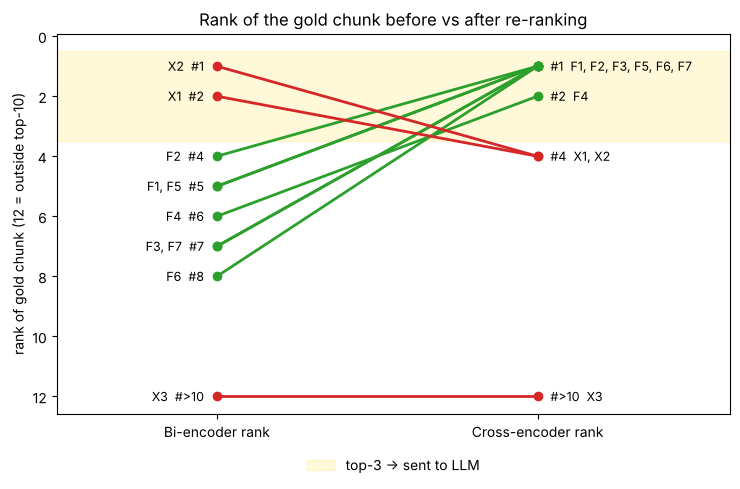

In [13]:
# Rank-shift slope chart for the failure and counter-example queries
import matplotlib.pyplot as plt
sub = shift[~shift.qid.str.startswith("G")]
fig, ax = plt.subplots(figsize=(7.5, 5))
left, right = {}, {}                                   # rank → list of query ids (so labels don't overlap)
for _, r in sub.iterrows():
    y1 = min(r.bi_rank, 12); y2 = int(r.ce_rank) if pd.notna(r.ce_rank) else 12
    col = "tab:green" if r.rerank_top3_has_gold and not r.baseline_top3_has_gold else ("tab:red" if r.qid.startswith("X") else "tab:gray")
    ax.plot([0, 1], [y1, y2], marker="o", color=col, lw=2)
    left.setdefault(y1, []).append(r.qid); right.setdefault(y2, []).append(r.qid)
for y, ids in left.items():
    ax.text(-0.04, y, f"{', '.join(ids)}  #{y if y < 12 else '>10'}", ha="right", va="center", fontsize=9)
for y, ids in right.items():
    ax.text(1.04, y, f"#{y if y < 12 else '>10'}  {', '.join(ids)}", ha="left", va="center", fontsize=9)
ax.axhspan(0.5, 3.5, color="gold", alpha=0.15, label="top-3 → sent to LLM")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Bi-encoder rank", "Cross-encoder rank"]); ax.set_xlim(-0.5, 1.6)
ax.invert_yaxis(); ax.set_ylabel("rank of gold chunk (12 = outside top-10)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
ax.set_title("Rank of the gold chunk before vs after re-ranking")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "rank_shift.png", dpi=150); plt.show()

## 10. Failure analysis: what each pipeline actually hands to the LLM

For each stress-test query, the table lists the 3 chunks each pipeline sends to the LLM. ★ marks a chunk that contains the answering clause.

In [14]:
def show_contexts(qid, width=150):
    q = qdf.set_index("qid").loc[qid]
    gold = set(q.gold_chunks)
    cands, rr = RUNS[qid]
    display(Markdown(f"### {qid} · {q.category}\n**Q:** {q.query}  \n**Gold clause:** “{q.gold_phrases[0]}…”"))
    tab = []
    for name, lst in [("Baseline", cands), ("Re-ranked", rr)]:
        for d in lst[:TOP_N_CONTEXT]:
            c = chunks[d["chunk_id"]]
            tab.append({"pipeline": name, "chunk": d["chunk_id"], "page": c["page_start"],
                        "bi_rank": d["bi_rank"], "ce_rank": d.get("ce_rank", "—"), "gold": "★" if d["chunk_id"] in gold else "",
                        "text": c["text"][:width] + "…"})
    display(pd.DataFrame(tab))

for qid in [q for q in all_q if not q.startswith("G")]:
    show_contexts(qid)

### F1 · Keyword trap / synonym
**Q:** Can a spectator tell the arbiter that a player's time has run out?  
**Gold clause:** “If a spectator sees a flag fall…”

,pipeline,chunk,page,bi_rank,ce_rank,gold,text
0,Baseline,105,40,1,—,,"Players do not need to record the moves, but do not lose their rights to claims normally based on a scoresheet. The ..."
1,Baseline,56,23,2,—,,a large digital countdown in the playing hall. For FIDE events with fewer than 30 players an announcement must be ma...
2,Baseline,101,38,3,—,,"the competition, 12.2.3 ensure that a good playing environment is maintained, 12.2.4 ensure that the players are not..."
3,Re-ranked,102,38,5,1,★,"moves completed, except in applying Article 8.5 when at least one flag has fallen. The arbiter shall refrain from in..."
4,Re-ranked,55,23,10,2,,"on all boards. Where the move-counter is used to add time after the first time control (at least 30 moves), it is de..."
5,Re-ranked,947,336,6,3,,"with the time control 25 minutes per player for all the game, with 10 seconds increment per move starting from move ..."


### F2 · Keyword trap / distractor
**Q:** Can a player who arrives late still store their mobile phone before playing?  
**Gold clause:** “opportunity to store his/her device…”

,pipeline,chunk,page,bi_rank,ce_rank,gold,text
0,Baseline,95,36,1,—,,"if, when the mobile phone is found, the opponent cannot checkmate the offending player by any series of legal moves:..."
1,Baseline,94,36,2,—,,"with these obligations, the arbiter shall take measures in accordance with Article 12.9. 11.3.4 Smoking, including e..."
2,Baseline,873,307,3,—,,"play the players are forbidden from using any electronic device, notes, sources of information or advice, or to anal..."
3,Re-ranked,96,36,4,1,★,violation of this article (perhaps a fine). They can also include in the regulations of the event the possibility of...
4,Re-ranked,95,36,1,2,,"if, when the mobile phone is found, the opponent cannot checkmate the offending player by any series of legal moves:..."
5,Re-ranked,881,309,5,3,,the camera. If the player refuses the arbiter should implement Article 10.9 as appropriate. An example of a situatio...


### F3 · Exception / corner case
**Q:** Can a player claim threefold repetition after touching a piece?  
**Gold clause:** “loses the right to claim a draw under Article 9.2…”

...

,pipeline,chunk,page,bi_rank,ce_rank,gold,text
0,Baseline,58,24,1,—,,"is reached between a flag fall and the fall being noticed, the result is not changed. The arbiter should announce fl..."
1,Baseline,109,41,2,—,★,"by the players without intervention of the arbiter. A.5.3 To claim a win on time, the claimant may pause the chesscl..."
2,Baseline,52,22,3,—,,normal to investigate whether 30 moves have been completed by both players only after a flag has fallen. If a move-c...
3,Re-ranked,136,52,5,1,,announced beforehand. III.2.2 These Guidelines shall apply only to standard chess and rapid chess games without incr...
4,Re-ranked,58,24,1,2,,"is reached between a flag fall and the fall being noticed, the result is not changed. The arbiter should announce fl..."
5,Re-ranked,77,30,8,3,,"scoresheets or approve the result on their electronic scoresheets. Even if incorrect, this result shall stand, unles..."


### X2 · Counter: CE demotes gold
**Q:** Can a player smoke during an online game with supervision?  
**Gold clause:** “not permitted when visible on camera…”

,pipeline,chunk,page,bi_rank,ce_rank,gold,text
0,Baseline,875,307,1,—,★,"in any manner whatsoever. This includes unreasonable claims, unreasonable offers of a draw, sending inappropriate me..."
1,Baseline,94,36,2,—,,"with these obligations, the arbiter shall take measures in accordance with Article 12.9. 11.3.4 Smoking, including e..."
2,Baseline,96,36,3,—,,violation of this article (perhaps a fine). They can also include in the regulations of the event the possibility of...
3,Re-ranked,96,36,3,1,,violation of this article (perhaps a fine). They can also include in the regulations of the event the possibility of...
4,Re-ranked,867,305,9,2,,the supervision of an arbiter. “Online chess” is the most generic term for Internet chess games. The regulations of ...
5,Re-ranked,3,1,6,3,,"leave the playing area every 10 or 15 minutes to smoke or vape, nor for any conversations with friends, spectators, ..."


### X3 · Counter: recall ceiling
**Q:** Can two players agree a draw before any moves have been made?  
**Gold clause:** “provided both players have made at least one move…”

,pipeline,chunk,page,bi_rank,ce_rank,gold,text
0,Baseline,84,32,1,—,,"1. make a move 2. offer of a draw 3. press the clock If a player deviates from this order, the offer still stands th..."
1,Baseline,85,32,2,—,,need to check the correctness of the claim. But be careful. If there is a draw restriction (for example: no draw off...
2,Baseline,80,31,3,—,,be attached to the offer. In both cases the offer cannot be withdrawn and remains valid until the opponent accepts i...
3,Re-ranked,81,31,9,1,,"the players to draw in less than the specified number of moves, which must be accepted by the arbiter. For example, ..."
4,Re-ranked,85,32,2,2,,need to check the correctness of the claim. But be careful. If there is a draw restriction (for example: no draw off...
5,Re-ranked,79,30,5,3,,he/she should go to that board and check if the players have recorded the result of the game and signed both scoresh...


## 11. Generate Answer 1 (baseline context) vs. Answer 2 (re-ranked context)

Same LLM, same prompt template, same decoding settings. The only variable is which three chunks are in the context.

In [15]:
answers = []
for qid in [q for q in all_q if not q.startswith("G")]:
    query = qdf.set_index("qid").loc[qid, "query"]
    cands, rr = RUNS[qid]
    p1, p2 = build_prompt(query, cands), build_prompt(query, rr)
    a1, t1 = generate(p1)
    a2, t2 = generate(p2)
    answers.append({"qid": qid, "query": query, "answer_1_baseline": a1, "answer_2_reranked": a2,
                    "llm_s_1": round(t1, 3), "llm_s_2": round(t2, 3)})
    if LLM_BACKEND == "gemini": time.sleep(4)        # stay under free-tier requests-per-minute limits

with open(RESULTS_DIR / "answers.json", "w") as f:
    json.dump({"backend": LLM_BACKEND, "model": globals().get("GEMINI_RESOLVED", GEMINI_MODEL) if LLM_BACKEND == "gemini" else HF_MODEL,
               "answers": answers}, f, indent=2, ensure_ascii=False)

if LLM_BACKEND == "none":
    print("LLM generation skipped (LLM_BACKEND=none). Example prompt that would be sent:\n")
    print(build_prompt(answers[0]["query"], RUNS[answers[0]["qid"]][0])[:1500], "…")
else:
    md_out = []
    for a in answers:
        md_out.append(f"### {a['qid']}: {a['query']}\n\n**Answer 1 (baseline):** {a['answer_1_baseline']}\n\n**Answer 2 (re-ranked):** {a['answer_2_reranked']}\n")
    (RESULTS_DIR / "answer_comparison.md").write_text("\n---\n".join(md_out))
    display(Markdown("\n---\n".join(md_out)))

LLM generation skipped (LLM_BACKEND=none). Example prompt that would be sent:

You are an assistant answering questions about the FIDE Arbiters' Manual 2026.
Answer the question using ONLY the context passages below. Quote the relevant rule or article number when possible.
If the context does not contain the information needed, say "The provided context does not contain this information."
Do not use outside knowledge.

### Context
[Passage 1 | p.40]
Players do not need to record the moves, but do not lose their rights to claims normally based on a scoresheet. The player can, at any time, ask the arbiter to provide him/her with a scoresheet, in order to write the moves. A.3 The penalties mentioned in Articles 7 and 9 of the Competitive Rules of Play shall be one minute instead of two minutes. A.4 The Competitive Rules of Play shall apply if: A4.1one arbiter supervises at most three games and A4.2 each game is recorded by the arbiter or his/her assistant and, if possible, by electronic m

## 12. Latency profiling

Each query is timed over 5 repetitions after a warm-up, broken down by stage:

* **Pipeline 1** = query encoding + FAISS search
* **Pipeline 2** = Pipeline 1 + cross-encoder scoring of the 10 pairs + sorting

LLM generation time is reported separately because it is the same kind of work in both pipelines (3 chunks of context).

In [16]:
REPEATS = 5
for _ in range(3): rerank("warm up", baseline_retrieve("warm up"))     # warm-up (lazy init, caches)

lat = []
for qid, query in zip(qdf.qid, qdf["query"]):
    for _ in range(REPEATS):
        t0 = time.perf_counter(); qv = bi_encoder.encode([query], normalize_embeddings=True).astype(np.float32)
        t1 = time.perf_counter(); s, i = index.search(qv, TOP_K_RETRIEVE)
        t2 = time.perf_counter()
        cands = [{"chunk_id": int(c), "bi_rank": r + 1} for r, c in enumerate(i[0])]
        t3 = time.perf_counter(); rerank(query, cands)
        t4 = time.perf_counter()
        lat.append({"qid": qid, "encode_ms": (t1-t0)*1e3, "faiss_ms": (t2-t1)*1e3, "rerank_ms": (t4-t3)*1e3})

lat = pd.DataFrame(lat)
lat["pipeline1_ms"] = lat.encode_ms + lat.faiss_ms
lat["pipeline2_ms"] = lat.pipeline1_ms + lat.rerank_ms
summary = lat[["encode_ms", "faiss_ms", "rerank_ms", "pipeline1_ms", "pipeline2_ms"]].describe(percentiles=[.5, .95]).T[["mean", "50%", "95%"]]
summary.columns = ["mean (ms)", "median (ms)", "p95 (ms)"]
summary = summary.round(2)
summary.to_csv(RESULTS_DIR / "latency_retrieval.csv")
display(summary)
print(f"Re-ranking overhead: {summary.loc['pipeline2_ms','median (ms)'] / summary.loc['pipeline1_ms','median (ms)']:.1f}× the baseline retrieval time (median) on {DEVICE}")

ans = pd.DataFrame(answers)
if ans.llm_s_1.notna().any() and LLM_BACKEND != "none":
    llm = pd.DataFrame({"LLM generation (s)": [ans.llm_s_1.mean(), ans.llm_s_2.mean()]}, index=["Answer 1", "Answer 2"]).round(2)
    llm.to_csv(RESULTS_DIR / "latency_llm.csv"); display(llm)

,mean (ms),median (ms),p95 (ms)
encode_ms,12.59,12.00,16.91
faiss_ms,0.20,0.20,0.25
rerank_ms,393.33,380.82,486.84
pipeline1_ms,12.79,12.19,17.12
pipeline2_ms,406.12,391.85,499.47


Re-ranking overhead: 32.1× the baseline retrieval time (median) on cpu


## 13. Scaling: why not run the cross-encoder over the whole corpus?

A direct test: score **all** chunks with the cross-encoder for a few queries, then compare cost and quality with retrieve-then-rerank.

In [17]:
def ce_full_corpus(query, batch_size=64):
    scores = cross_encoder.predict([(query, t) for t in chunk_texts], batch_size=batch_size, show_progress_bar=False)
    return list(np.argsort(-scores))

full_rows = []
for qid in ["F3", "F6", "X3", "G7"]:
    query = qdf.set_index("qid").loc[qid, "query"]; gold = set(qdf.set_index("qid").loc[qid, "gold_chunks"])
    t0 = time.perf_counter(); order = ce_full_corpus(query); t_full = time.perf_counter() - t0
    t0 = time.perf_counter(); rr = rerank(query, baseline_retrieve(query)); t_2stage = time.perf_counter() - t0
    full_rows.append({"qid": qid, "full-corpus CE (s)": round(t_full, 2), "two-stage (s)": round(t_2stage, 3),
                      "slow-down": f"{t_full / t_2stage:.0f}×",
                      "gold rank (full CE)": next(r + 1 for r, c in enumerate(order) if c in gold),
                      "gold rank (two-stage)": next((d["ce_rank"] for d in rr if d["chunk_id"] in gold), "not in top-10")})
full_df = pd.DataFrame(full_rows); full_df.to_csv(RESULTS_DIR / "full_corpus_ce.csv", index=False)
print(f"corpus = {len(chunks)} chunks → full-corpus CE needs {len(chunks)} transformer passes per query vs {TOP_K_RETRIEVE} for re-ranking")
full_df

corpus = 1005 chunks → full-corpus CE needs 1005 transformer passes per query vs 10 for re-ranking


,qid,full-corpus CE (s),two-stage (s),slow-down,gold rank (full CE),gold rank (two-stage)
0,F3,76.65,0.433,177×,2,1
1,F6,75.50,0.551,137×,2,1
2,X3,74.58,0.365,204×,9,not in top-10
3,G7,75.89,0.798,95×,1,1


## 14. Summary

* **Rank shifts:** on every `F*` stress test the answering chunk sits at bi-encoder rank 4–8, outside what the LLM sees. The cross-encoder moves it into the top 3 (to #1 in six of seven cases). See the table in §9 and `results/rank_shift.png`.
* **Aggregate:** across all queries, Hit@3 and MRR@10 rise after re-ranking (§9). On the general queries the gain is smaller, because most are already easy for the bi-encoder.
* **Not a free win:** re-ranking can demote a correct chunk (`X1`, `X2`), and it cannot fix a recall failure (`X3`: gold chunk at bi-encoder rank > 10).
* **Cost:** re-ranking 10 pairs costs one cross-encoder batch per query. Scoring the whole corpus costs roughly two orders of magnitude more per query (§13), which is why the cross-encoder is only used as a second stage.

The full discussion is in `REPORT.md`.